## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [52]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Roney Nguyen]

**Date:** [10/19/2026]

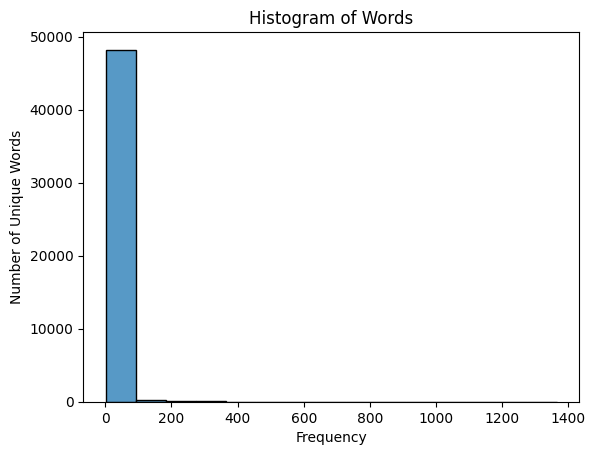

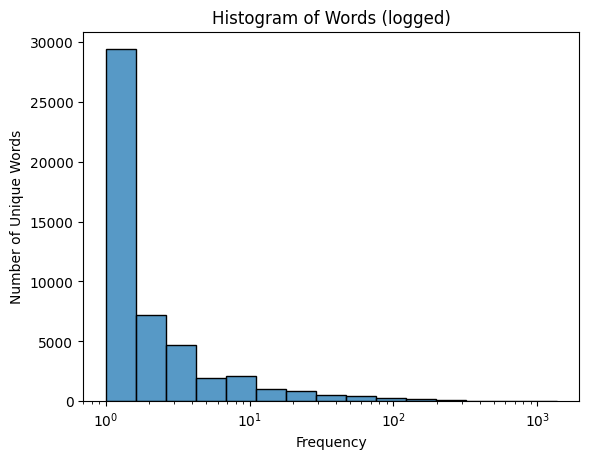

In [1]:
# Your Phase 1 solution to the problem goes here.
#Q1, run code
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

#Plot Histogram of all words
counts = [count for token, count in token_freq]

sns.histplot(counts, bins=15).set(title="Histogram of Words")
plt.xlabel("Frequency")
plt.ylabel("Number of Unique Words")
plt.show()

sns.histplot(counts, bins=15, log_scale=True).set(title="Histogram of Words (logged)")
plt.xlabel("Frequency")
plt.ylabel("Number of Unique Words")
plt.show()
#The frequency of tokens is very right skewed, 0-100/first bar makes up almost the entirety of the graph reaching up to ~50000, even after being scaled for log it is still apparent. This means that most unique words are only said a couple of times.


In [2]:
#Q2
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pyarrow.parquet as pq

#Load data
table = pq.read_table("data/Phishing_clean.parquet")
df = table.to_pandas()

#1. Perform Train-test split
X = df.drop(columns=["Email Type"])
Y = df["Email Type"]
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=65
)

#2. Run regression of y
model = LinearRegression()
model.fit(X_train, Y_train)
#Run R^2 on test set
test_r2 = model.score(X_test, Y_test)
print("Test R2:", test_r2, "\n")
#On training set
train_r2 = model.score(X_train, Y_train)
print("Train R2:", train_r2, "\n")
#Test R2 is 0.657 and Train R2 is 0.767

#3. What words have the largest coefficients in absolute value and most strongly influence predictions
coefs = pd.Series(model.coef_, index=X.columns)
print("Top 10 Largest Coefficients:")
print(coefs.loc[coefs.abs().sort_values(ascending=False).head(10).index])
#The words that have the largest coefficient is aging, helvetica, localized, and background-image. Most seem to be css and html words rather than actual email content, but the most popular aging isn't.

Test R2: 0.6571173475409766 

Train R2: 0.7677733084118992 

Top 10 Largest Coefficients:
aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:   -0.780070
thermal              0.671019
12px;                0.629280
rcs                  0.553536
exercise!            0.542180
burning             -0.515023
#000000;             0.502902
dtype: float64


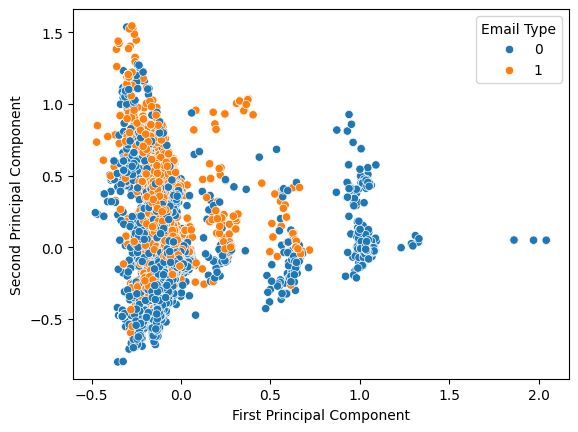

In [7]:
#Q3
from sklearn.decomposition import PCA

#Perform a PCA decomp
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

#Plot the first two principal component in a scatter plot and hue the points by scam
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=Y)
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.show()
#Some patterns I see are that majority of the emails are below 0.0 FPC
#The higher the SPC, the more common fake emails are. 
#Fake emails tend to cluster around eachother.
#Almost all outliers in FPC are real emails.


In [ ]:
#Q4
#pca of 2610
pca = PCA(n_components=2610, svd_solver="full")
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

#run lin reg
linear_pca = LinearRegression()
linear_pca.fit(X_train_pca, Y_train)

#R2 of train and test
test_r2 = linear_pca.score(X_test_pca, Y_test)
print("Test PCA: ", test_r2, '\n')
train_r2 = linear_pca.score(X_train_pca, Y_train)
print("Train PCA: ", train_r2, '\n')
#Test R2 is 0.661 and Train R2 is 0.766

#Check linear regression values
print("Linear Regression Test: ", model.score(X_test, Y_test))
print("Linear Regression Train:", model.score(X_train, Y_train))
#Linear Test R2 is 0.657 and Train R2 is 0.767

#The performance of this compared to inear regression is nearly identical. Both are different from the linear regression values by the thousandths decimals, negligible.

Test PCA:  0.6613559301353324 

Train PCA:  0.7668967611277833 

Linear Regression Test:  0.6571173475409766
Linear Regression Train: 0.7677733084118992


In [12]:
#Q5
#Using principal components helps reduce the number of variables in the regression while keeping most of the important information. 
#It also removes issues with variables being highly correlated with each other, making the model simpler and reducing the risk of overfitting.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** `82aabd60b31f4f5778ecfc380dbc8ef927d5592c`
- **AI tool and model used:** OpenAI Codex, GPT-6
- **Review scope:** Fresh review of the committed Phase 1 solution. Phase 1 is preserved unchanged.

### *Prompts used

1. Examine part 2 of the code, determine possible improvements, redunancy, errors, etc that I would need to change. Return the answer in a concise numbered list.

### *AI-proposed changes


1. Quantify the token-frequency pattern with the median and the fraction of tokens occurring at most ten times, alongside the histograms.
2. Interpret the largest regression coefficients using their signs and training-set token support; distinguish conditional associations from causal effects or overall feature importance.
3. Make the two-component PCA plot easier to assess with transparent points, named classes, and explained-variance labels; describe overlap and verify any apparent clustering.
4. Encapsulate predictive PCA and regression in a training-only pipeline, preserve the original split for a fair comparison, and calculate scores, score differences, and retained variance directly instead of copying results into comments.
5. Explain that PCA retains predictor variance rather than predictive relevance, and distinguish possible benefits from guarantees, especially when only 101 of 2,711 components are removed.

### *Evaluation of AI suggestions


**Draft evaluation for student review:** These decisions describe the revisions implemented below. Review them and make the final decisions your own before submission.

| Change | Proposed decision | Reason and verification |
|---|---|---|
| 1 | Accept | Numerical summaries make the histogram interpretation checkable; calculated from all unique-token counts. |
| 2 | Accept | Signed coefficients show the direction of each association. Training support helps contextualize estimates based on few emails; it does not establish stability or causality. |
| 3 | Accept | Transparency reduces overplotting, and explained variance indicates how much of the original variation the display represents. Interpretation is checked against the rendered plot. |
| 4 | Accept | The pipeline keeps the predictive PCA fit inside the training data. Both models use the same original 80/20 split with random_state=65; printed comparisons come directly from fitted models. |
| 5 | Accept | The revised explanation avoids promising improved prediction or no overfitting, and uses the actual retained variance and component count. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

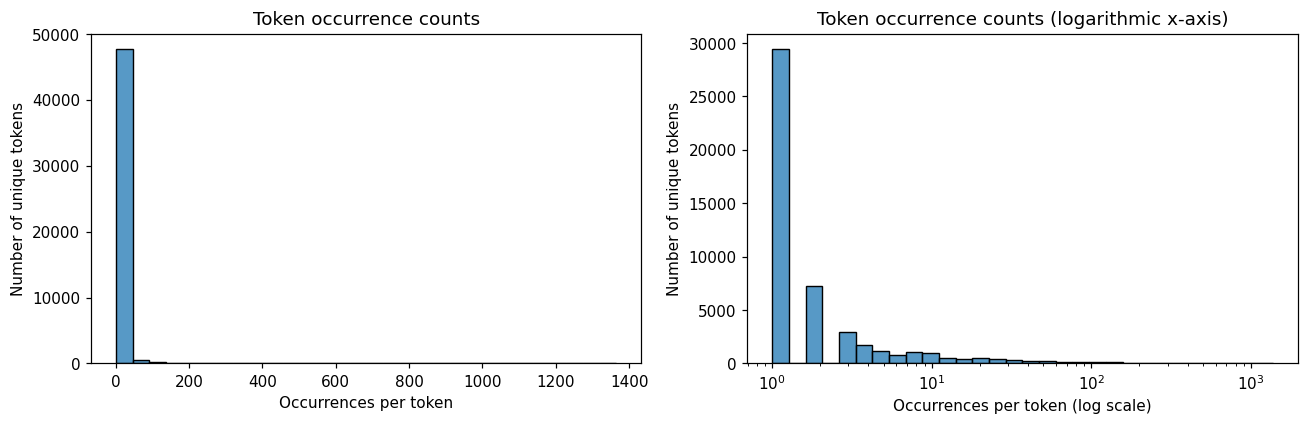

Unique tokens: 48,691
Median occurrences per token: 1
Tokens occurring at most 10 times: 92.41%
Maximum occurrences of one token: 1,365


In [1]:
# Phase 2: independent setup; no Phase 1 variables are required.
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Q1: distribution of occurrence counts across unique tokens
with open("data/all_tokens.pickle", "rb") as file:
    token_counts = Counter(pickle.load(file))
counts = np.array(list(token_counts.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(counts, bins=30, ax=axes[0])
sns.histplot(counts, bins=30, log_scale=True, ax=axes[1])
axes[0].set(title="Token occurrence counts", xlabel="Occurrences per token",
            ylabel="Number of unique tokens")
axes[1].set(title="Token occurrence counts (logarithmic x-axis)",
            xlabel="Occurrences per token (log scale)", ylabel="Number of unique tokens")
fig.tight_layout()
plt.show()

print(f"Unique tokens: {len(counts):,}")
print(f"Median occurrences per token: {np.median(counts):.0f}")
print(f"Tokens occurring at most 10 times: {(counts <= 10).mean():.2%}")
print(f"Maximum occurrences of one token: {counts.max():,}")

**Q1 interpretation.** The distribution is strongly right-skewed: most unique tokens are rare, and a small number occur much more often. The median and the percentage printed above quantify this pattern. The logarithmic x-axis spreads out the smaller counts; it does not change the underlying observations.

In [2]:
# Q2: keep the original split so changes in scores are comparable.
df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=65
)

ols = LinearRegression()
ols.fit(X_train, y_train)
ols_train_r2 = ols.score(X_train, y_train)
ols_test_r2 = ols.score(X_test, y_test)
print(f"OLS training R²: {ols_train_r2:.6f}")
print(f"OLS test R²:     {ols_test_r2:.6f}")

coefficients = pd.Series(ols.coef_, index=X.columns)
top_tokens = coefficients.abs().nlargest(10).index
coefficient_details = pd.DataFrame({
    "coefficient": coefficients.loc[top_tokens],
    "training emails containing token": X_train.loc[:, top_tokens].ne(0).sum(),
})
print("\nTop 10 tokens by absolute coefficient (signs preserved):")
print(coefficient_details.to_string(float_format=lambda value: f"{value:.6f}"))

OLS training R²: 0.767773
OLS test R²:     0.657117

Top 10 tokens by absolute coefficient (signs preserved):
                   coefficient  training emails containing token
aging                 0.996514                                45
helvetica,            0.892177                                17
localized             0.787934                                30
background-image:    -0.780070                                26
thermal               0.671019                                15
12px;                 0.629280                                14
rcs                   0.553536                                15
exercise!             0.542180                                22
burning              -0.515023                                28
#000000;              0.502902                                16


**Q2 interpretation.** Positive coefficients increase the fitted phishing score when that token is present, holding the other token features fixed; negative coefficients decrease it. The list includes ordinary words as well as formatting tokens such as `helvetica,`, `background-image:`, and `12px;`. It would be inaccurate to describe all the largest-coefficient tokens as HTML/CSS.

Coefficient magnitude answers the assignment's ranking question, but does not alone measure overall importance: token prevalence and correlations also matter. Training-set support provides context for estimates based on few emails. These are conditional associations, not evidence that particular words cause phishing. R² is the requested regression measure, not classification accuracy; linear predictions are not constrained to the interval [0, 1].

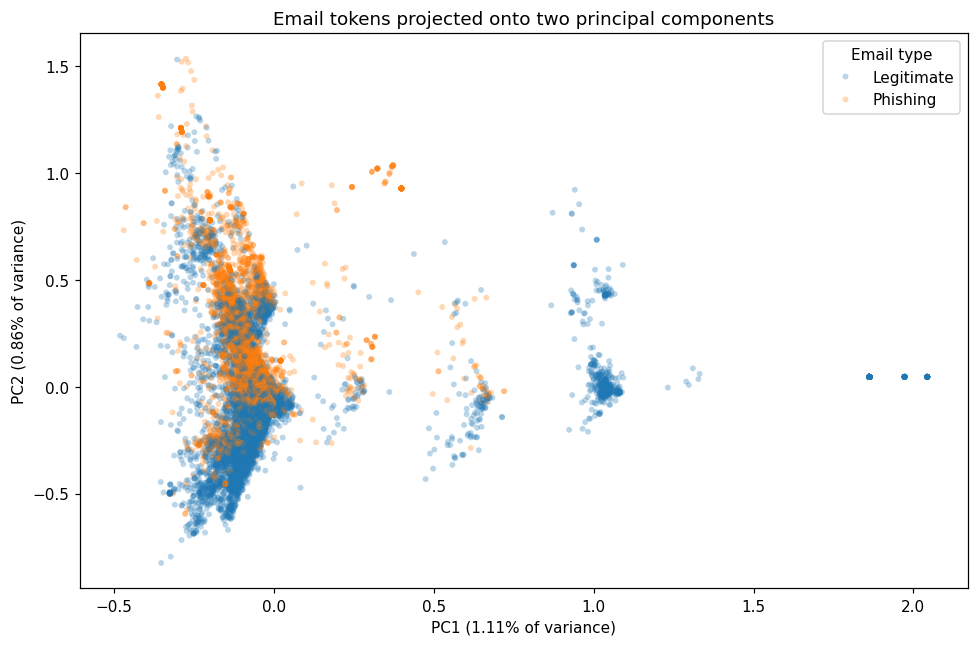

Variance represented by this plot: 1.97%


In [3]:
# Q3: descriptive visualization of the full dataset, separate from prediction.
# This PCA is never used by the predictive model in Q4.
pca_visual = PCA(n_components=2, svd_solver="randomized", random_state=65)
coordinates = pca_visual.fit_transform(X)
variance = pca_visual.explained_variance_ratio_
plot_data = pd.DataFrame({
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1],
    "Email type": y.map({0: "Legitimate", 1: "Phishing"}).to_numpy(),
})

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Email type",
                hue_order=["Legitimate", "Phishing"],
                alpha=0.3, s=15, linewidth=0, ax=ax)
ax.set(title="Email tokens projected onto two principal components",
       xlabel=f"PC1 ({variance[0]:.2%} of variance)",
       ylabel=f"PC2 ({variance[1]:.2%} of variance)")
fig.tight_layout()
plt.show()
print(f"Variance represented by this plot: {variance.sum():.2%}")

**Q3 interpretation.** The two classes overlap substantially in the dense central region, so these two components do not cleanly separate legitimate and phishing emails. In this orientation, phishing emails are more visible in the upper part of the central cloud, while several groups farther to the right consist mostly of legitimate emails. The first two components explain only about 1.97% of the total predictor variance, so this display gives a limited view of the full dataset. PCA axis signs can reverse without changing the underlying geometry; the positive direction itself has no inherent phishing meaning.

In [4]:
# Q4: PCA is fitted only on the training emails inside the pipeline.
pcr = Pipeline([
    ("pca", PCA(n_components=2610, svd_solver="full")),
    ("regression", LinearRegression()),
])
pcr.fit(X_train, y_train)
pcr_train_r2 = pcr.score(X_train, y_train)
pcr_test_r2 = pcr.score(X_test, y_test)

print(f"OLS: training R² = {ols_train_r2:.6f}, test R² = {ols_test_r2:.6f}")
print(f"PCR: training R² = {pcr_train_r2:.6f}, test R² = {pcr_test_r2:.6f}")
print(f"PCR minus OLS training R²: {pcr_train_r2 - ols_train_r2:+.6f}")
print(f"PCR minus OLS test R²:     {pcr_test_r2 - ols_test_r2:+.6f}")
retained_variance = pcr.named_steps["pca"].explained_variance_ratio_.sum()
print(f"Training predictor variance retained: {retained_variance:.4%}")
print(f"Components removed: {X.shape[1] - pcr.named_steps['pca'].n_components_}")

OLS: training R² = 0.767773, test R² = 0.657117
PCR: training R² = 0.766897, test R² = 0.661356
PCR minus OLS training R²: -0.000877
PCR minus OLS test R²:     +0.004239
Training predictor variance retained: 99.9850%
Components removed: 101


**Q4 interpretation.** The two regressions perform similarly. On this split, principal component regression (PCR) has slightly lower training R² and slightly higher test R² than ordinary regression. The printed differences quantify how small the change is; one test split does not establish a reliable improvement on future data. Keeping 2,610 of 2,711 components retains almost all predictor variance, so this is only a modest dimensionality reduction.

**Q5.** PCA replaces correlated token features with components that are uncorrelated on the training data. Dropping components can simplify a high-dimensional regression and reduce sensitivity to low-variance directions, potentially reducing overfitting. However, PCA chooses directions that explain variation in X without using the outcome. Low-variance directions can still be useful for predicting phishing, so retaining more predictor variance does not guarantee better predictions. Here, removing only 101 components produces a small change in performance. Choosing a different number of components would require validation within the training data, keeping the test set reserved for final evaluation.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements that AI gave to me that directly affected my code and answers were giving more support for my explanations and helping me understand the limitations of PCA. For example, AI added the percentage of tokens that appeared ten times or fewer, which made my explanation about the histogram being right skewed more specific. It also added the explained variance to my PCA graph, showing that the first two components only represented about 1.97% of the total variance. This was useful because even though I could see some patterns, the graph only showed a small part of the information in the dataset. Another improvement was showing how many training emails contained the words with the largest coefficients, since having a large coefficient does not necessarily mean that a word is important overall. Some limitations were redundancy, such as using a pipeline when my original code already fitted PCA only on the training data, so this change did not really affect my answers. The revised solution was verified by running the revised code, checking the graphs, and comparing the training and test R² values for both models. Overall, AI did not significantly change my results, but it helped explain what those results actually supported.